In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold, KFold, cross_val_score
from src.data_loader import load_split
from src.preprocessing import CorrelationFilter

sns.set_theme()
RANDOM_STATE = 42
X_train, y_train, s_train = load_split("train")

In [2]:
other = [c for c in X_train.columns if not c.startswith(("t", "f"))]
print(len(other))
print(other)

7
['angle(tBodyAccMean,gravity)', 'angle(tBodyAccJerkMean),gravityMean)', 'angle(tBodyGyroMean,gravityMean)', 'angle(tBodyGyroJerkMean,gravityMean)', 'angle(X,gravityMean)', 'angle(Y,gravityMean)', 'angle(Z,gravityMean)']


In [3]:
for threshold in [0.99, 0.95, 0.90]:
    cf = CorrelationFilter(threshold).fit(X_train)
    print(f"threshold {threshold}: dropped {cf.drop_mask_.sum()}, kept {cf.keep_mask_.sum()}")

threshold 0.99: dropped 122, kept 439
threshold 0.95: dropped 308, kept 253
threshold 0.9: dropped 359, kept 202


In [4]:
cv = GroupKFold(n_splits=5)   # groups = volunteers

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "SVM (RBF)": SVC(),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
}

def cv_accuracy(steps, model):
    """Mean and std of accuracy across 5 volunteer-grouped folds."""
    pipe = Pipeline(steps + [("model", model)])
    scores = cross_val_score(pipe, X_train, y_train, groups=s_train, cv=cv, scoring="accuracy")
    return scores.mean(), scores.std()

In [5]:
rows = []
for name, model in models.items():
    for use_scaler in [False, True]:
        steps = [("scaler", StandardScaler())] if use_scaler else []
        mean, std = cv_accuracy(steps, model)
        rows.append({"model": name, "scaled": use_scaler,
                     "cv_accuracy": round(mean, 4), "std": round(std, 4)})

scaling_results = pd.DataFrame(rows)
print(scaling_results)
scaling_results.to_csv("../reports/m3_scaling_comparison.csv", index=False)

                 model  scaled  cv_accuracy     std
0  Logistic Regression   False       0.9387  0.0404
1  Logistic Regression    True       0.9343  0.0393
2            SVM (RBF)   False       0.9343  0.0425
3            SVM (RBF)    True       0.9231  0.0408
4        Random Forest   False       0.9167  0.0431
5        Random Forest    True       0.9165  0.0448


In [6]:
rows = []
for threshold in [1.0, 0.99, 0.95, 0.90]:         # 1.0 = no filtering
    n_kept = CorrelationFilter(threshold).fit(X_train).keep_mask_.sum()
    for name, model in models.items():
        steps = [("corr_filter", CorrelationFilter(threshold)), ("scaler", StandardScaler())]
        mean, std = cv_accuracy(steps, model)
        rows.append({"threshold": threshold, "features_kept_full_train": n_kept, "model": name,
                     "cv_accuracy": round(mean, 4), "std": round(std, 4)})

filter_results = pd.DataFrame(rows)
print(filter_results)
filter_results.to_csv("../reports/m3_correlation_threshold.csv", index=False)

    threshold  features_kept_full_train                model  cv_accuracy  \
0        1.00                       561  Logistic Regression       0.9343   
1        1.00                       561            SVM (RBF)       0.9231   
2        1.00                       561        Random Forest       0.9165   
3        0.99                       439  Logistic Regression       0.9396   
4        0.99                       439            SVM (RBF)       0.9242   
5        0.99                       439        Random Forest       0.9285   
6        0.95                       253  Logistic Regression       0.9310   
7        0.95                       253            SVM (RBF)       0.9209   
8        0.95                       253        Random Forest       0.9265   
9        0.90                       202  Logistic Regression       0.9305   
10       0.90                       202            SVM (RBF)       0.9206   
11       0.90                       202        Random Forest       0.9174   

In [7]:
random_cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for name in ["Logistic Regression", "Random Forest"]:
    pipe = Pipeline([("scaler", StandardScaler()), ("model", models[name])])
    random_scores = cross_val_score(pipe, X_train, y_train, cv=random_cv)
    group_scores = cross_val_score(pipe, X_train, y_train, groups=s_train, cv=GroupKFold(n_splits=5))
    print(f"{name}: random split {random_scores.mean():.4f} | volunteer-grouped {group_scores.mean():.4f}")

Logistic Regression: random split 0.9842 | volunteer-grouped 0.9343
Random Forest: random split 0.9811 | volunteer-grouped 0.9165


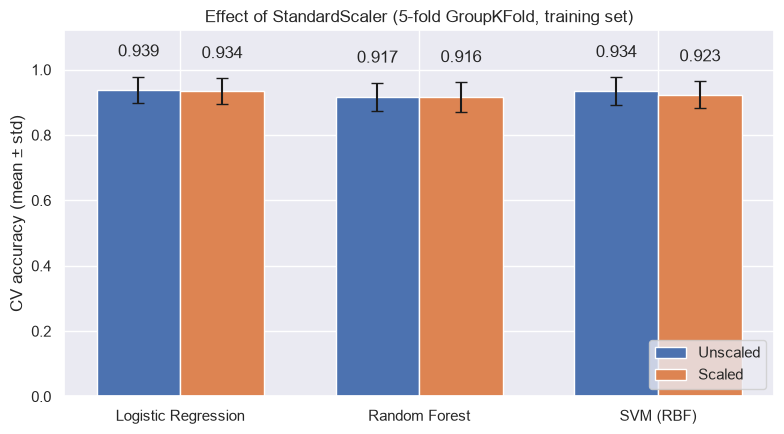

In [13]:
# Mean accuracy with error bars (+/- 1 std across the 5 volunteer-grouped folds)
means = scaling_results.pivot(index="model", columns="scaled", values="cv_accuracy")
stds = scaling_results.pivot(index="model", columns="scaled", values="std")
model_names = means.index.tolist()
x = np.arange(len(model_names))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 4.5))
bars_unscaled = ax.bar(x - width / 2, means[False], width, yerr=stds[False], capsize=4, label="Unscaled")
bars_scaled = ax.bar(x + width / 2, means[True], width, yerr=stds[True], capsize=4, label="Scaled")
ax.bar_label(bars_unscaled, fmt="%.3f", padding=12)
ax.bar_label(bars_scaled, fmt="%.3f", padding=12)

ax.set_xticks(x)
ax.set_xticklabels(model_names)
ax.set_ylim(0, 1.12)
ax.set_ylabel("CV accuracy (mean ± std)")
ax.set_title("Effect of StandardScaler (5-fold GroupKFold, training set)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("../reports/figures/scaling_comparison.png", dpi=150)
plt.show()